# SCA Homework 1 – Forecasting Airline Passengers
Parts I–IV.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")

Matplotlib is building the font cache; this may take a moment.


In [2]:
# load data
df = pd.read_csv("data/Homework1_TSA130.csv")
df = df.dropna()
df["Date"] = pd.to_datetime(df["Date"], format="%b-%y")

y = df.set_index("Date")["Number of Passengers (x1000)"]
y = y.asfreq("MS")

print(len(y), "months, missing values:", y.isna().sum())
y.head()

130 months, missing values: 0


Date
2014-01-01    113.0
2014-02-01    119.0
2014-03-01    139.0
2014-04-01    129.0
2014-05-01    124.0
Freq: MS, Name: Number of Passengers (x1000), dtype: float64

## I. Visualisation

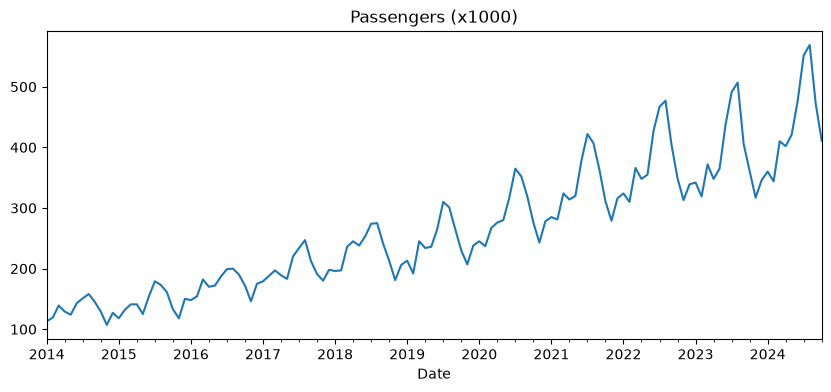

In [3]:
# time series
y.plot(figsize=(10, 4), title="Passengers (x1000)")
plt.show()

Plotting one line per year

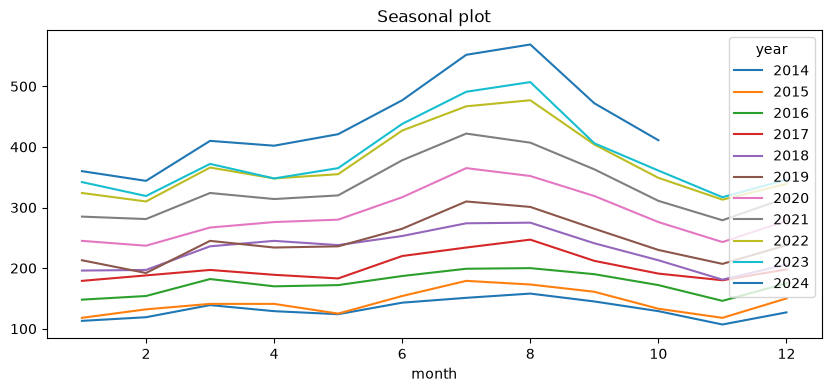

In [4]:

df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
table = df.pivot(index="month", columns="year", values="Number of Passengers (x1000)")
table.plot(figsize=(10, 4), title="Seasonal plot")
plt.show()

Total per year

In [5]:
y.groupby(y.index.year).sum()

Date
2014    1584.0
2015    1725.0
2016    2095.0
2017    2418.0
2018    2755.0
2019    2936.0
2020    3455.0
2021    4000.0
2022    4479.0
2023    4612.0
2024    4418.0
Name: Number of Passengers (x1000), dtype: float64

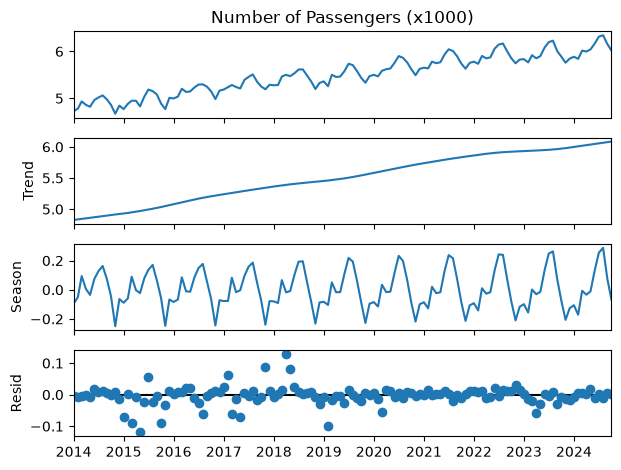

Date
2015-05-01   -3.832415
2017-11-01    3.017498
2018-04-01    4.326006
2019-02-01   -3.119425
Name: resid, dtype: float64

In [6]:
# decomposition of log(y) into trend, season and residual
stl = STL(np.log(y), period=12, robust=True).fit()
stl.plot()
plt.show()

#Months with a large residual
resid = stl.resid
z = (resid - resid.mean()) / resid.std()
z[abs(z) > 3]

- 130 months (Jan-14 to Oct-24), 2024 runs only to October.
- A few STL residuals stand out (May-15, Apr-18), but they are small in absolute terms.
- Clear upward trend (flattening in 2023–24) and yearly seasonality, with a peak in Jul – Aug.
- Seasonal swings grow with the level -> multiplicative, so we model log(y).

## II. Stationarity
ADF test: H₀ = unit root (non-stationary), so p < 0.05 means stationary.

In [7]:
ly = np.log(y)
for name, x in [("log y", ly), ("first difference", ly.diff()),
                ("seasonal difference", ly.diff(12)), ("both differences", ly.diff().diff(12))]:
    print(name, " ADF p =", round(adfuller(x.dropna())[1], 3))

log y  ADF p = 0.638
first difference  ADF p = 0.017
seasonal difference  ADF p = 0.067
both differences  ADF p = 0.004


- log y: ADF p = 0.64, so non-stationary.
- First difference: ADF p = 0.017, but the seasonal pattern is still there, so a seasonal difference is also needed.
- Both differences: ADF p = 0.004, so stationary. Use d = 1, D = 1.

## III. Models
Last 12 months are the test set (for part IV).

In [8]:
train = y[:-12]
test_set = y[-12:]

### (a) Exponential smoothing (Holt-Winters)
Try all trend/seasonal options, pick the lowest AIC.

In [9]:
results = []
for trend in ["additive", "multiplicative"]:
    for damped in [False, True]:
        for seasonal in ["additive", "multiplicative"]:
            m = ExponentialSmoothing(train, trend=trend, damped_trend=damped,
                                     seasonal=seasonal, seasonal_periods=12).fit()
            results.append([trend, damped, seasonal, m.aic])

results = pd.DataFrame(results, columns=["trend", "damped", "seasonal", "AIC"])
results.sort_values("AIC")

,trend,damped,seasonal,AIC
1,additive,False,multiplicative,590.976821
5,multiplicative,False,multiplicative,592.505838
7,multiplicative,True,multiplicative,592.515549
3,additive,True,multiplicative,597.001134
0,additive,False,additive,622.042682
4,multiplicative,False,additive,624.635751
6,multiplicative,True,additive,626.551587
2,additive,True,additive,627.737036


In [10]:
# best model
ets = ExponentialSmoothing(train, trend="additive", damped_trend=False,
                           seasonal="multiplicative", seasonal_periods=12).fit()
ets.params

{'smoothing_level': np.float64(0.2859776589966525),
 'smoothing_trend': np.float64(0.0),
 'smoothing_seasonal': np.float64(0.6498818482545372),
 'damping_trend': nan,
 'initial_level': np.float64(130.55918495540774),
 'initial_trend': np.float64(2.6883772601306815),
 'initial_seasons': array([0.8469876 , 0.88336   , 0.99187067, 0.91866688, 0.85119235,
        0.96989576, 1.02780266, 1.04247066, 0.95693956, 0.84953208,
        0.73633844, 0.8778012 ]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

### (b) SARIMA on log y
d = 1, D = 1 from part II. Look at ACF/PACF, then try small models and pick the lowest AIC.

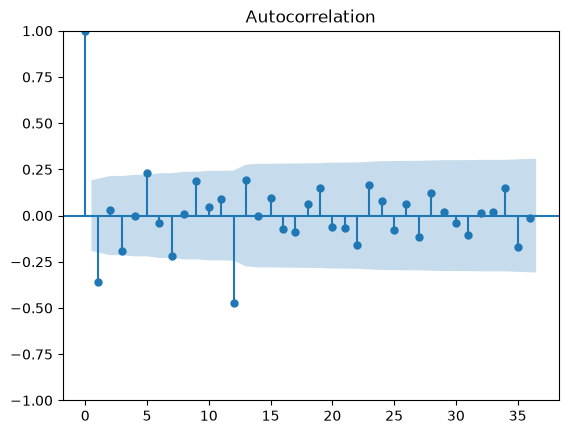

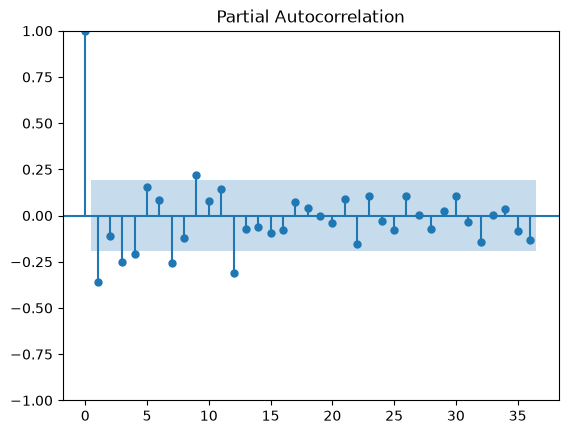

In [11]:
log_train = np.log(train)
x = log_train.diff().diff(12).dropna()

plot_acf(x, lags=36)
plot_pacf(x, lags=36)
plt.show()

ACF spikes at lag 1 and 12, so MA(1) and SMA(1).

In [12]:
results = []
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
    m = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
    results.append([p, q, P, Q, m.aic])

results = pd.DataFrame(results, columns=["p", "q", "P", "Q", "AIC"])
results.sort_values("AIC").head()

,p,q,P,Q,AIC
5,0,1,0,1,-347.325861
7,0,1,1,1,-347.252555
6,0,1,1,0,-346.210431
17,1,1,0,1,-346.044650
9,0,2,0,1,-345.681883


In [13]:
# best model
sarima = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima.summary())

#res should be white noise with p > 0.05
acorr_ljungbox(sarima.resid[13:], lags=[12, 24])

                                     SARIMAX Results                                      
Dep. Variable:       Number of Passengers (x1000)   No. Observations:                  118
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 176.663
Date:                            Fri, 30 Oct 2026   AIC                           -347.326
Time:                                    11:32:48   BIC                           -339.364
Sample:                                01-01-2014   HQIC                          -344.100
                                     - 10-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4709      0.090     -5.232      0.000      -0.647      -0.295
ma.S.L12      -0.5835      0.114   

,lb_stat,lb_pvalue
12,12.734534,0.388628
24,23.152970,0.510783


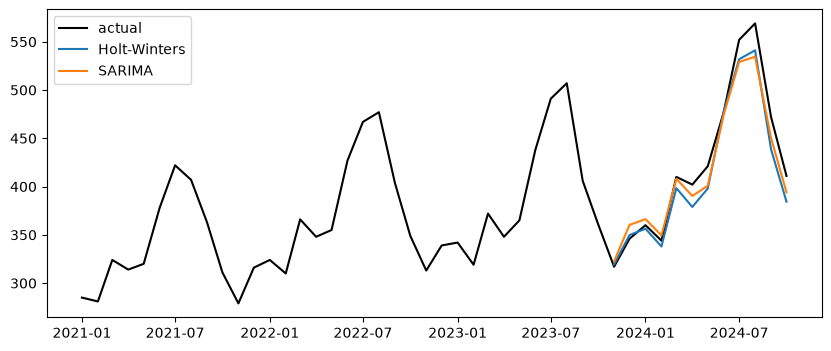

In [14]:
#Forecasts for the test year
fc_ets = ets.forecast(12)
fc_sarima = np.exp(sarima.forecast(12))

plt.figure(figsize=(10, 4))
plt.plot(y["2021":], color="black", label="actual")
plt.plot(fc_ets, label="Holt-Winters")
plt.plot(fc_sarima, label="SARIMA")
plt.legend()
plt.show()

- ETS: additive trend + multiplicative seasonality has the lowest AIC.
- SARIMA(0,1,1)(0,1,1)_12 on log y (the "airline model"); both MA terms are significant, Ljung-Box p > 0.05 so white-noise residuals.
- Both models follow the test year closely

## IV. Model Evaluation

Both models are evaluated on the last 12 months, excluded from model fitting.

Bias is forecast minus actual: positive means overforecasting; negative means underforecasting. Bias, RMSE and MAE are in thousands of passengers; MAPE is a percentage.

In [15]:
def evaluate_forecast(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    error = forecast - actual

    return {
        "Bias": np.mean(error),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAE": np.mean(np.abs(error)),
        "MAPE (%)": 100 * np.mean(np.abs(error / actual)),
    }

evaluation = pd.DataFrame({
    "Holt-Winters": evaluate_forecast(test_set, fc_ets),
    "SARIMA": evaluate_forecast(test_set, fc_sarima),
}).T

evaluation = evaluation.sort_values("RMSE")
display(evaluation.round(3))


,Bias,RMSE,MAE,MAPE (%)
SARIMA,-8.421,16.673,13.685,3.075
Holt-Winters,-14.059,18.894,15.214,3.413


### Evaluation results and conclusion

On the held-out period November 2023-October 2024, SARIMA has lower RMSE (16.673 versus 18.894), MAE (13.685 versus 15.214), and MAPE (3.075% versus 3.413%) than Holt-Winters. SARIMA is therefore preferred for forecast accuracy on this test period.

Both models have negative bias, so they underforecast demand on average. SARIMA's bias is -8.421 thousand passengers per month (about 8,421 passengers below actual demand), compared with -14.059 thousand for Holt-Winters. SARIMA also has the smaller absolute bias. Its MAE corresponds to an average absolute error of about 13,685 passengers per month.

These results describe one 12-month test period and do not guarantee future performance. For capacity planning, the tendency to underforecast should be considered alongside the prediction intervals developed in Part V.
